# Fictitious Play

Each player best responds to the opponent’s empirical action frequencies. In this zero-sum game the averages can approach equilibrium even as the chosen actions keep changing.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Empirical best responses

Both players choose simultaneously from the counts at the start of a round. Ties are broken at random.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gallery.games import ZERO_SUM, gap, show_mixes, trace_plot


def tied_best(values, rng):
    return int(rng.choice(np.flatnonzero(np.isclose(values, values.max()))))

## Follow the average strategies

One pseudocount per action defines an initial belief. The reported summaries use actual plays only.

Final best-response gap 0.0278 | Average realised payoff 0.2964 | Independent-mix value 0.2856
Row frequencies: [5.704e-01 4.295e-01 1.000e-04] Column frequencies: [0.4226 0.5774 0.    ]


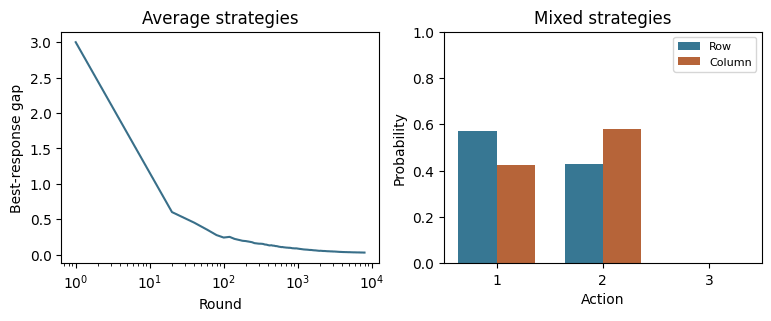

In [3]:
A = ZERO_SUM.copy()
rng = np.random.default_rng(17)
rows = np.zeros(3)
cols = np.zeros(3)
history = []
realised = 0.0
for t in range(1, 8001):
    r = tied_best(A @ (cols + 1), rng)
    c = tied_best(-((rows + 1) @ A), rng)
    realised += A[r, c]
    rows[r] += 1
    cols[c] += 1
    if t == 1 or t % 20 == 0:
        history.append((t, gap(A, rows / t, cols / t)))
p, q = rows / t, cols / t
print(
    f"Final best-response gap {gap(A,p,q):.4f} | Average realised payoff {realised/t:.4f} | Independent-mix value {p@A@q:.4f}"
)
print("Row frequencies:", p.round(4), "Column frequencies:", q.round(4))
trace_plot(history, p, q)
plt.show()

## Reading the result

The realised payoff uses matched actions from the same round. Multiplying the two marginal distributions gives a different quantity.

## References

[Robinson, An Iterative Method of Solving a Game (1951)](https://doi.org/10.2307/1969530)

[Nashpy, algorithms and definitions](https://nashpy.readthedocs.io/en/stable/text-book/index.html)

[Payoff matrix and best-response diagnostics](../../gallery/games.py)